In [1]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 100
INITIAL_STATE = jnp.array(
    [0.0, 0.0, 0.0, 1.0]
)  # x, y, theta, v, heading right at 1 m/s

In [2]:
from hcnn.system_dynamics import SystemDynamicsBike

sys_dynamics = SystemDynamicsBike.factory(
    wheelbase=2.5, max_steering=0.5, dt=0.2
)  # 100 * 0.2s * 1m/s -> 20m

In [3]:
from flax import struct

from hcnn.system_constraints import SystemConstraintsBase


@struct.dataclass
class SystemConstraintsSlalom(SystemConstraintsBase):
    state_dim: int
    action_dim: int
    constraint_dim: int
    lower_bound: jax.Array
    upper_bound: jax.Array
    center1: jax.Array
    radius1: float
    center2: jax.Array
    radius2: float
    center3: jax.Array
    radius3: float

    @classmethod
    def factory(cls):
        return cls(
            state_dim=4,
            action_dim=2,
            constraint_dim=3,
            lower_bound=jnp.ones(3),
            upper_bound=jnp.ones(3) * jnp.inf,
            center1=jnp.array([05.0, -0.2]),
            radius1=1.0,
            center2=jnp.array([10.0, +0.2]),
            radius2=1.0,
            center3=jnp.array([15.0, -0.2]),
            radius3=1.0,
        )

    def __call__(self, state: jax.Array, action: jax.Array) -> jax.Array:
        state_xy = state[..., 0:2]

        diff1 = state_xy - self.center1
        val1 = jnp.sum(diff1 * diff1, axis=-1, keepdims=True) - (
            self.radius1 * self.radius1
        )

        diff2 = state_xy - self.center2
        val2 = jnp.sum(diff2 * diff2, axis=-1, keepdims=True) - (
            self.radius2 * self.radius2
        )

        diff3 = state_xy - self.center3
        val3 = jnp.sum(diff3 * diff3, axis=-1, keepdims=True) - (
            self.radius3 * self.radius3
        )

        return jnp.concatenate([val1, val2, val3], axis=-1)


sys_constraints = SystemConstraintsSlalom.factory()

In [4]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = jnp.array([0.0, 0.0])  # no steering, no acceleration
    next_state = sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [5]:
raw_rollout.states[-1]

Array([19.800003,  0.      ,  0.      ,  1.      ], dtype=float32)

In [6]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters

projection_problem = ProjectionProblem.factory(
    sys_dynamics=sys_dynamics,
    sys_constraints=sys_constraints,
    horizon=HORIZON,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters(
    alpha=1.6,
    sigma=1,
    rho=0.1,
    rho_equality_mult=1e3,
    tol_prim=1e-4,
    tol_dual=1e-4,
    epsilon=0.1,
    max_iter_lin=2000,
    max_iter_nonlin=25,
    ls_c1=1e-4,
    ls_rho=0.5,
    ls_max_iter=10,
    ls_penalty_weight=10.0,
)

In [7]:
# from hcnn.solver import sqp_solve

# x_star, sqp_info = sqp_solve(sqp_problem, sqp_parameters)
# optvar = projection_problem.x_to_optvar(x_star)
# proj_rollout = Rollout(
#     states=optvar.states,
#     actions=optvar.actions,
# )

In [8]:
# Manual SQP iterations to log residuals
from functools import partial

import jax.numpy as jnp

from hcnn.solver.solver_sqp import SQPVariables, sqp_step

# Initialize SQP variables
variables = SQPVariables.factory(problem=sqp_problem, parameters=sqp_parameters)

# Lists to store residuals
primal_residuals = []
dual_residuals = []

step_jit = jax.jit(
    partial(sqp_step, problem=sqp_problem, parameters=sqp_parameters)
)

for i in range(sqp_parameters.max_iter_nonlin):
    print(f"Iteration {i + 1}")
    variables = step_jit(variables)
    primal_residuals.append(variables.max_primal_residual)
    dual_residuals.append(variables.max_dual_residual)

# Convert lists to JAX arrays for plotting
primal_residuals = jnp.stack(primal_residuals)
dual_residuals = jnp.stack(dual_residuals)

# Extract final solution
x_star_manual = variables.x
optvar = projection_problem.x_to_optvar(x_star_manual)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

Iteration 1
Iteration 2
Iteration 3
Iteration 4
Iteration 5
Iteration 6
Iteration 7
Iteration 8
Iteration 9
Iteration 10
Iteration 11
Iteration 12
Iteration 13
Iteration 14
Iteration 15
Iteration 16
Iteration 17
Iteration 18
Iteration 19
Iteration 20
Iteration 21
Iteration 22
Iteration 23
Iteration 24
Iteration 25


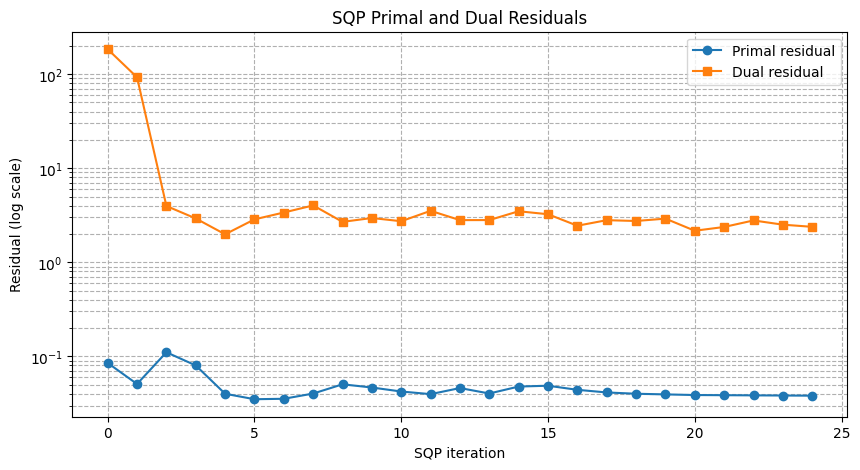

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(primal_residuals, label="Primal residual", marker="o")
ax.plot(dual_residuals, label="Dual residual", marker="s")
ax.set_yscale("log")
ax.set_xlabel("SQP iteration")
ax.set_ylabel("Residual (log scale)")
ax.set_title("SQP Primal and Dual Residuals")
ax.legend()
ax.grid(True, which="both", linestyle="--")
plt.show()

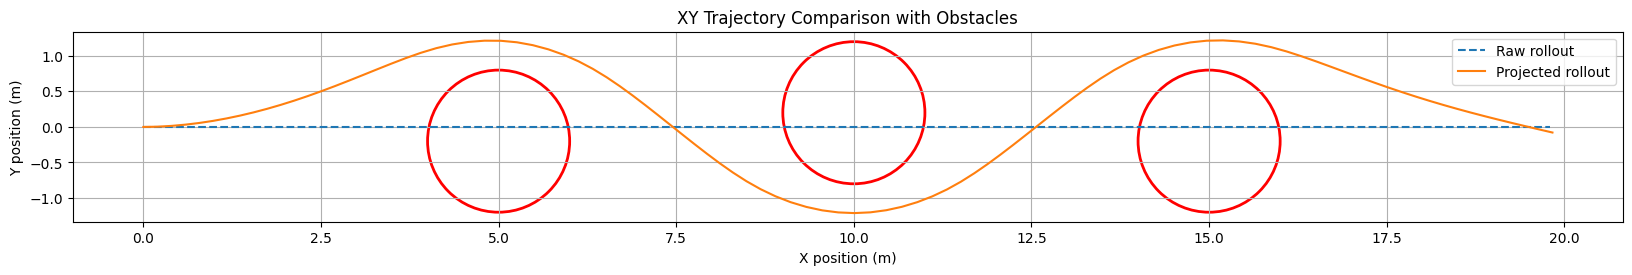

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

raw_xy = raw_rollout.states[:, :2]
proj_xy = proj_rollout.states[:, :2]

fig, ax = plt.subplots(figsize=(20, 5))
ax.plot(raw_xy[:, 0], raw_xy[:, 1], label="Raw rollout", linestyle="--")
ax.plot(proj_xy[:, 0], proj_xy[:, 1], label="Projected rollout", linestyle="-")

# draw circular obstacles
for center, radius in [
    (sys_constraints.center1, sys_constraints.radius1),
    (sys_constraints.center2, sys_constraints.radius2),
    (sys_constraints.center3, sys_constraints.radius3),
]:
    obstacle = Circle(
        tuple(center), radius, edgecolor="red", facecolor="none", linewidth=2
    )
    ax.add_patch(obstacle)

ax.set_xlabel("X position (m)")
ax.set_ylabel("Y position (m)")
ax.set_title("XY Trajectory Comparison with Obstacles")
ax.legend()
ax.grid(True)
ax.set_aspect("equal")
plt.show()

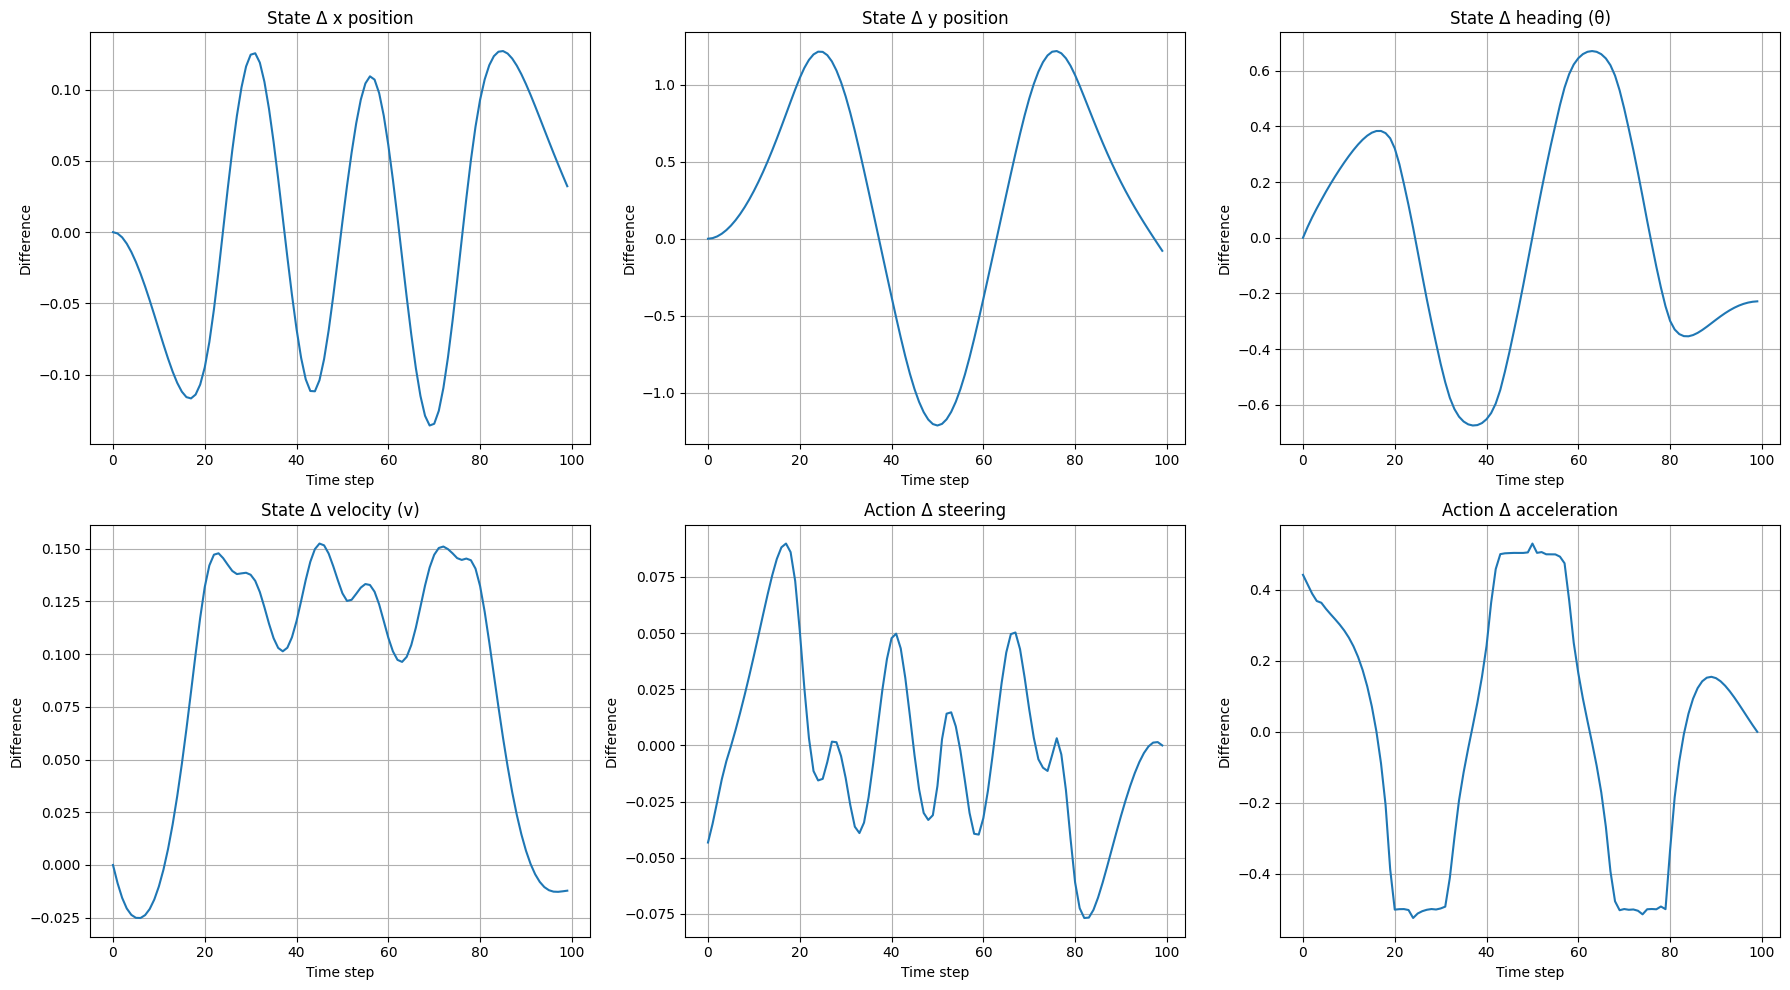

In [11]:
# compute differences between projected and raw rollouts
state_diff = proj_rollout.states - raw_rollout.states
action_diff = proj_rollout.actions - raw_rollout.actions

time = jnp.arange(HORIZON)

# prepare subplots: 4 state dims + 2 action dims
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
state_labels = ["x position", "y position", "heading (θ)", "velocity (v)"]
action_labels = ["steering", "acceleration"]

# plot state differences
for i in range(4):
    ax = axs.flat[i]
    ax.plot(time, state_diff[:, i])
    ax.set_title(f"State Δ {state_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True)

# plot action differences
for i in range(2):
    ax = axs.flat[4 + i]
    ax.plot(time, action_diff[:, i])
    ax.set_title(f"Action Δ {action_labels[i]}")
    ax.set_xlabel("Time step")
    ax.set_ylabel("Difference")
    ax.grid(True)

plt.tight_layout()
plt.show()